In [5]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, KBinsDiscretizer
from sklearn.linear_model import LinearRegression, Ridge, LassoCV

df = pd.read_csv("../data/clean.csv")
num_cols = [
    "age", "Medu", "Fedu", "traveltime", "studytime", "failures",
    "famrel", "freetime", "goout", "Dalc", "Walc", "health", "absences", "G1", "G2",
]
cat_cols = [
    "school", "sex", "address", "famsize", "Pstatus", "Mjob", "Fjob", "reason",
    "guardian", "schoolsup", "famsup", "paid", "activities", "nursery",
    "higher", "internet", "romantic",
]

train, test = train_test_split(df, test_size=0.25, random_state=42)
X_train, y_train = train[num_cols + cat_cols], train["G3"]
X_test, y_test = test[num_cols + cat_cols], test["G3"]

top_feat = train[num_cols].corrwith(train["G3"]).abs().idxmax()
print("Самый сильный числовой признак:", top_feat)

X = np.column_stack([np.ones(len(train)), train[top_feat]])
y = train["G3"].to_numpy()

w_inv = np.linalg.inv(X.T @ X) @ X.T @ y
w_solve = np.linalg.solve(X.T @ X, X.T @ y)
w_lstsq = np.linalg.lstsq(X, y, rcond=None)[0]
lr = LinearRegression().fit(train[[top_feat]], y)

print("inv:  ", w_inv.round(4))
print("solve:", w_solve.round(4))
print("lstsq:", w_lstsq.round(4))
print("sklearn:", round(lr.intercept_, 4), lr.coef_.round(4))

print("\n--- Добавляем копию столбца", top_feat, "---")
X_dup = np.column_stack([np.ones(len(train)), train[top_feat], train[top_feat]])
for name, fn in [
    ("inv", lambda: np.linalg.inv(X_dup.T @ X_dup) @ X_dup.T @ y),
    ("solve", lambda: np.linalg.solve(X_dup.T @ X_dup, X_dup.T @ y)),
    ("lstsq", lambda: np.linalg.lstsq(X_dup, y, rcond=None)[0]),
]:
    try:
        print(name, fn().round(4))
    except np.linalg.LinAlgError as e:
        print(name, "ОШИБКА:", e)

lr_dup = LinearRegression().fit(
    np.column_stack([train[top_feat], train[top_feat]]), y
)
print("sklearn:", round(lr_dup.intercept_, 4), lr_dup.coef_.round(4))

Самый сильный числовой признак: G2
inv:   [-0.0559  1.0343]
solve: [-0.0559  1.0343]
lstsq: [-0.0559  1.0343]
sklearn: -0.0559 [1.0343]

--- Добавляем копию столбца G2 ---
inv ОШИБКА: Singular matrix
solve ОШИБКА: Singular matrix
lstsq [-0.0559  0.5172  0.5172]
sklearn: -0.0559 [0.5172 0.5172]


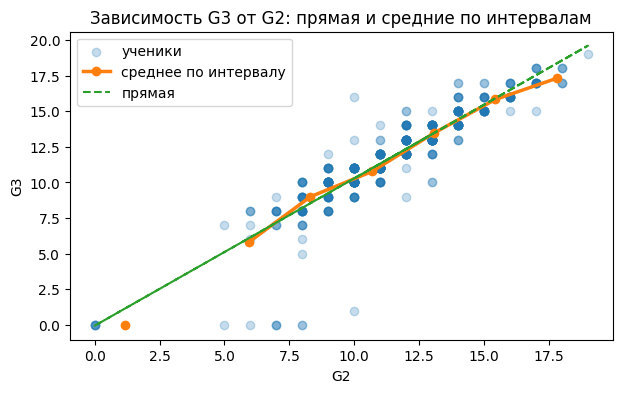

uniform  n_bins= 4 -> cv_r2=0.7618
uniform  n_bins= 8 -> cv_r2=0.8042
uniform  n_bins=12 -> cv_r2=0.8021
uniform  n_bins=20 -> cv_r2=0.7975
quantile n_bins= 4 -> cv_r2=0.6987
quantile n_bins= 8 -> cv_r2=0.7562
quantile n_bins=12 -> cv_r2=0.7752
quantile n_bins=20 -> cv_r2=0.7859


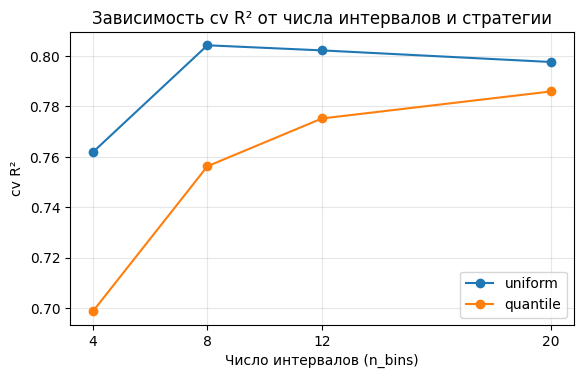

In [6]:
# График нелинейности: среднее G3 по 8 интервалам G2 vs прямая
bins_plot = pd.cut(train["G2"], bins=8)
means = train.groupby(bins_plot, observed=False)["G3"].mean()
mids = [iv.mid for iv in means.index]

plt.figure(figsize=(7, 4))
plt.scatter(train["G2"], train["G3"], alpha=0.25, label="ученики")
plt.plot(mids, means.values, "o-", linewidth=2.5, color="tab:orange", label="среднее по интервалу")
plt.plot(train["G2"], lr.predict(train[["G2"]]), "--", color="tab:green", label="прямая")
plt.xlabel("G2")
plt.ylabel("G3")
plt.title("Зависимость G3 от G2: прямая и средние по интервалам")
plt.legend()
plt.show()

num_wo = [c for c in num_cols if c != "G2"]
cat_pipe = make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore"))
num_pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler())

results_bins = {"uniform": [], "quantile": []}
n_list = [4, 8, 12, 20]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    for strat in ["uniform", "quantile"]:
        for nb in n_list:
            prep_b = make_column_transformer(
                (num_pipe, num_wo),
                (make_pipeline(SimpleImputer(strategy="median"),
                               KBinsDiscretizer(n_bins=nb, encode="onehot", strategy=strat)), ["G2"]),
                (cat_pipe, cat_cols),
            )
            s = cross_val_score(make_pipeline(prep_b, LinearRegression()), X_train, y_train, cv=5, scoring="r2").mean()
            results_bins[strat].append(s)
            print(f"{strat:8} n_bins={nb:2} -> cv_r2={s:.4f}")

plt.figure(figsize=(6.5, 3.8))
for strat, vals in results_bins.items():
    plt.plot(n_list, vals, "o-", label=strat)
plt.xticks(n_list)
plt.xlabel("Число интервалов (n_bins)")
plt.ylabel("cv R²")
plt.title("Зависимость cv R² от числа интервалов и стратегии")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

Лучшее alpha Ridge: 21.5443, min cv_rmse=1.3416


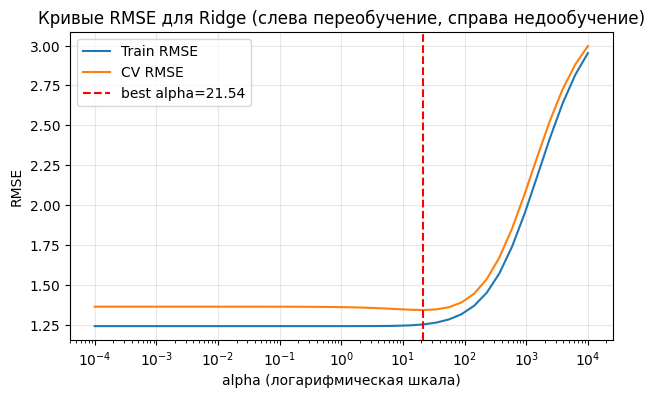


drop=None: alpha=0.0889, cv_r2=0.8341, cv_rmse=1.3143
Обнулено весов: 50 из 58
Примеры обнулённых: ['age', 'Medu', 'Fedu', 'traveltime', 'famrel', 'goout', 'Walc', 'school_GP', 'school_MS', 'sex_F', 'sex_M', 'address_R', 'address_U', 'famsize_GT3', 'famsize_LE3']

drop=first: alpha=0.0889, cv_r2=0.8342, cv_rmse=1.3138
Обнулено весов: 33 из 41
Примеры обнулённых: ['age', 'Medu', 'Fedu', 'traveltime', 'famrel', 'goout', 'Walc', 'school_MS', 'sex_M', 'address_U', 'famsize_LE3', 'Pstatus_T', 'Mjob_health', 'Mjob_other', 'Mjob_services']


In [7]:
prep = make_column_transformer((num_pipe, num_cols), (cat_pipe, cat_cols))
alphas = np.logspace(-4, 4, 40)
train_rmse, cv_rmse_list = [], []

for a in alphas:
    m = make_pipeline(prep, Ridge(alpha=a))
    cv_s = -cross_val_score(m, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error").mean()
    m.fit(X_train, y_train)
    tr_pred = m.predict(X_train)
    tr_rmse = np.sqrt(np.mean((y_train - tr_pred) ** 2))
    train_rmse.append(tr_rmse)
    cv_rmse_list.append(cv_s)

best_idx = int(np.argmin(cv_rmse_list))
best_alpha = alphas[best_idx]
print(f"Лучшее alpha Ridge: {best_alpha:.4f}, min cv_rmse={cv_rmse_list[best_idx]:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(alphas, train_rmse, label="Train RMSE")
plt.plot(alphas, cv_rmse_list, label="CV RMSE")
plt.axvline(best_alpha, color="red", linestyle="--", label=f"best alpha={best_alpha:.2f}")
plt.xscale("log")
plt.xlabel("alpha (логарифмическая шкала)")
plt.ylabel("RMSE")
plt.title("Кривые RMSE для Ridge (слева переобучение, справа недообучение)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# LassoCV без drop="first" и с drop="first"
for drop_opt in [None, "first"]:
    prep_l = make_column_transformer(
        (num_pipe, num_cols),
        (make_pipeline(SimpleImputer(strategy="most_frequent"),
                       OneHotEncoder(drop=drop_opt, handle_unknown="ignore")), cat_cols),
    )
    lasso_m = make_pipeline(prep_l, LassoCV(alphas=np.logspace(-4, 1, 40), cv=5, random_state=42, max_iter=50000))
    cv_r2_l = cross_val_score(lasso_m, X_train, y_train, cv=5, scoring="r2").mean()
    cv_rmse_l = -cross_val_score(lasso_m, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error").mean()
    lasso_m.fit(X_train, y_train)
    names_l = [n.split("__")[1] for n in lasso_m[:-1].get_feature_names_out()]
    coefs_l = pd.Series(lasso_m[-1].coef_, index=names_l)
    zeros = coefs_l[coefs_l.abs() < 1e-6].index.tolist()
    print(f"\ndrop={drop_opt}: alpha={lasso_m[-1].alpha_:.4f}, cv_r2={cv_r2_l:.4f}, cv_rmse={cv_rmse_l:.4f}")
    print(f"Обнулено весов: {len(zeros)} из {len(coefs_l)}")
    print("Примеры обнулённых:", zeros[:15])

In [8]:
best_model = make_pipeline(prep, Ridge(alpha=best_alpha))
base_cv = cross_val_score(best_model, X_train, y_train, cv=5, scoring="r2").mean()
best_model.fit(X_train, y_train)
names = [n.split("__")[1] for n in best_model[:-1].get_feature_names_out()]
coefs = pd.Series(best_model[-1].coef_, index=names)
print("Топ-10 весов по модулю:")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10).round(3))

drop_imp = {}
for col in num_cols + cat_cols:
    nn = [c for c in num_cols if c != col]
    cc = [c for c in cat_cols if c != col]
    p_tmp = make_column_transformer((num_pipe, nn), (cat_pipe, cc))
    s = cross_val_score(make_pipeline(p_tmp, Ridge(alpha=best_alpha)), X_train, y_train, cv=5, scoring="r2").mean()
    drop_imp[col] = base_cv - s

imp_s = pd.Series(drop_imp).sort_values(ascending=False)
print("\nТоп-10 важности через удаление (падение cv R²):")
print(imp_s.head(10).round(4))
print("Корреляция G1 и G2:", round(X_train[["G1", "G2"]].corr().iloc[0, 1], 3))

# Логарифм цели (log1p, т.к. в G3 есть нули)
print("\nАсимметрия y_train:", round(y_train.skew(), 3))
log_model = TransformedTargetRegressor(
    regressor=make_pipeline(prep, Ridge(alpha=best_alpha)),
    func=np.log1p,
    inverse_func=np.expm1,
)
log_cv = cross_val_score(log_model, X_train, y_train, cv=5, scoring="r2").mean()
log_model.fit(X_train, y_train)
log_coefs = pd.Series(log_model.regressor_[-1].coef_, index=names)
pct_effect = (np.exp(log_coefs) - 1) * 100
print("cv R² модели на log1p(G3):", round(log_cv, 4))
print("Топ-5 процентных эффектов на (G3 + 1) при росте признака на 1 ст. откл.:")
print(pct_effect.reindex(pct_effect.abs().sort_values(ascending=False).index).head(5).round(2))

Топ-10 весов по модулю:
G2               2.159
G1               0.674
Fjob_at_home     0.239
reason_other    -0.219
Mjob_other      -0.219
Fjob_services   -0.191
reason_course    0.147
failures        -0.144
Medu            -0.133
school_GP        0.128
dtype: float64

Топ-10 важности через удаление (падение cv R²):
G2           0.1526
G1           0.0047
Mjob         0.0027
failures     0.0008
school       0.0006
famsup       0.0003
Medu         0.0002
freetime     0.0001
studytime   -0.0000
nursery     -0.0001
dtype: float64
Корреляция G1 и G2: 0.856

Асимметрия y_train: -0.991
cv R² модели на log1p(G3): 0.5242
Топ-5 процентных эффектов на (G3 + 1) при росте признака на 1 ст. откл.:
G2               37.60
Medu             -4.93
absences          4.62
Mjob_other       -4.46
reason_course     4.29
dtype: float64
